# 04 — Evaluation on the held-out set

`data/eval_heldout.jsonl` has 40 requests written separately from the prompt's
few-shot examples and from `data/train.jsonl` (no overlap). Tools are **not**
executed during evaluation.

> Honesty note: the held-out set was used once to spot failure categories
> (recall vs clarify), after which two few-shot *categories* were added. A fresh
> test set should be written before reporting final numbers.

In [1]:
# --- setup: make the repo importable and quiet logs ---
import os, sys, logging
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
os.environ.setdefault("HF_HUB_OFFLINE", "1")  # models are already cached → fully local
logging.basicConfig(level=logging.WARNING)
print("repo:", ROOT)

repo: /Users/siavash/Projects/articles/narrow-ai-with-kv


In [2]:
import pandas as pd, matplotlib.pyplot as plt, numpy as np
from narrow_ai.settings import load_settings
from narrow_ai.models.model_registry import create_backend
from narrow_ai.evaluation.runner import EvaluationRunner
from narrow_ai.evaluation.dataset import load_eval_cases
cases = load_eval_cases(ROOT / "data/eval_heldout.jsonl")
s = load_settings(); s.model.backend = "mlx"
backend = create_backend(s)
print(len(cases), "cases")

40 cases


In [3]:
def evaluate(constrained=True, few_shot=True):
    s.model.constrained, s.model.few_shot = constrained, few_shot
    return EvaluationRunner(s, backend).run_cases(cases)

rep = evaluate()
print(f"intent accuracy {rep.metrics.accuracy:.3f} | param accuracy {rep.param_accuracy:.3f} | "
      f"malformed {rep.metrics.malformed_rate:.3f} | mean latency {rep.latency_ms_mean:.0f} ms")
pd.DataFrame([c.__dict__ for c in rep.cases if not (c.intent_ok and c.params_ok)])[
    ["utterance", "expected", "predicted", "parameters"]]

intent accuracy 0.925 | param accuracy 0.900 | malformed 0.000 | mean latency 332 ms


,utterance,expected,predicted,parameters
0,locate any swift files,search_files,search_files,"{'pattern': '*swift', 'workspace': 'active'}"
1,do the thing,clarify_request,unsupported,{'reason': 'Destructive actions are not allowed'}
2,make it better,clarify_request,unsupported,{'reason': 'Destructive actions are not allowed'}
3,check that,clarify_request,unsupported,{'reason': 'Command not supported'}


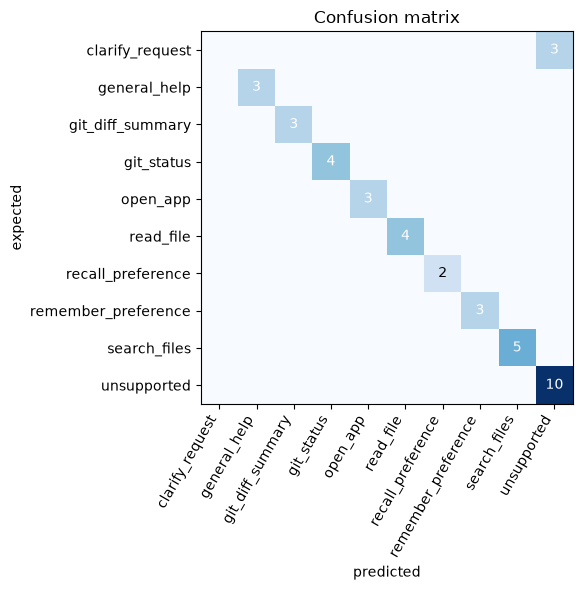

In [4]:
labels = sorted(set(c.expected for c in rep.cases) | set(c.predicted for c in rep.cases))
M = np.zeros((len(labels), len(labels)), int)
for c in rep.cases:
    M[labels.index(c.expected), labels.index(c.predicted)] += 1
fig, ax = plt.subplots(figsize=(7, 6))
ax.imshow(M, cmap="Blues")
ax.set_xticks(range(len(labels)), labels, rotation=60, ha="right"); ax.set_yticks(range(len(labels)), labels)
for i in range(len(labels)):
    for j in range(len(labels)):
        if M[i, j]:
            ax.text(j, i, M[i, j], ha="center", va="center", color="white" if M[i, j] > 2 else "black")
ax.set_xlabel("predicted"); ax.set_ylabel("expected"); ax.set_title("Confusion matrix")
plt.tight_layout(); plt.show()

## Ablation: few-shot × constrained decoding

In [5]:
rows = []
for fs in (False, True):
    for con in (False, True):
        r = evaluate(constrained=con, few_shot=fs)
        rows.append({"few_shot": fs, "constrained": con, "intent_acc": r.metrics.accuracy,
                     "param_acc": r.param_accuracy, "malformed": r.metrics.malformed_rate,
                     "fallback": r.fallback_rate, "latency_ms": round(r.latency_ms_mean)})
ablation = pd.DataFrame(rows)
ablation.to_csv(ROOT / "artifacts/ablation.csv", index=False)
ablation

question
  Extra inputs are not permitted [type=extra_forbidden, input_value="what's the capital of France", input_type=str]
    For further information visit https://errors.pydantic.dev/2.14/v/extra_forbidden); retrying once
question
  Extra inputs are not permitted [type=extra_forbidden, input_value="what's the capital of France", input_type=str]
    For further information visit https://errors.pydantic.dev/2.14/v/extra_forbidden); retrying once


,few_shot,constrained,intent_acc,param_acc,malformed,fallback,latency_ms
0,False,False,0.850,0.75,0.025,0.025,344
1,False,True,0.850,0.75,0.025,0.025,267
2,True,False,0.925,0.90,0.000,0.000,287
3,True,True,0.925,0.90,0.000,0.000,312


## Interactive: evaluate one configuration

In [ ]:
import ipywidgets as W
from IPython.display import display
fs = W.Checkbox(value=True, description="few-shot"); co = W.Checkbox(value=True, description="constrained")
b = W.Button(description="Run eval", button_style="primary"); o = W.Output()
def go(_):
    with o:
        o.clear_output(); r = evaluate(co.value, fs.value)
        print(f"intent {r.metrics.accuracy:.3f} · params {r.param_accuracy:.3f} · malformed {r.metrics.malformed_rate:.3f}")
b.on_click(go); display(W.HBox([fs, co, b]), o)

Output()